# Access eddies data

WATER is an ESA funded project that studies the population of active eddies based on SWOT-enriched and conventional satellite altimetry. Active eddies are surface SLA pattern that include a colocalized SST environmental anomaly.

* Original data:  https://zenodo.org/records/22917676
* Project Website: https://www.cmcc.it/projects/esa_water-wide-swath-altimetry-for-eddy-reconstruction
* Code repository: https://github.com/andcipollonecmcc/Eddy_Detection_Water/

The dataset comes in two zarr stores that have eddie counts and temperature anomaly data.

In [12]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

nadir_href = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/water-project/nadir_eddies.zarr/'
swot_href = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/water-project/swot_eddies.zarr/'


sst_var = "sea-surface-temperature-anomaly"
n_days = 7
crs = ccrs.PlateCarree()

## Nadir eddies

In [6]:
nadir_eddies = xr.open_zarr(nadir_href)
nadir_eddies

<xarray.Dataset> Size: 27GB
Dimensions:                          (time: 280, y: 1701, x: 3600)
Coordinates:
  * time                             (time) datetime64[ns] 2kB 2023-07-27 ......
Dimensions without coordinates: y, x
Data variables:
    eddies                           (time, y, x) float32 7GB dask.array<chunksize=(5, 1701, 3600), meta=np.ndarray>
    lat                              (time, y, x) float32 7GB dask.array<chunksize=(5, 1701, 3600), meta=np.ndarray>
    lon                              (time, y, x) float32 7GB dask.array<chunksize=(5, 1701, 3600), meta=np.ndarray>
    sea-surface-temperature-anomaly  (time, y, x) float32 7GB dask.array<chunksize=(5, 1701, 3600), meta=np.ndarray>
Attributes:
    history:  Wed Sep 23 14:38:25 2026: ncks -x -v SSH,temp,temp_noeddy Detec...
    NCO:      netCDF Operators version 5.0.6 (Homepage = http://nco.sf.net, C...

Text(0.5, 0.98, 'Nadir · 2023-07-27 to 2023-08-02')

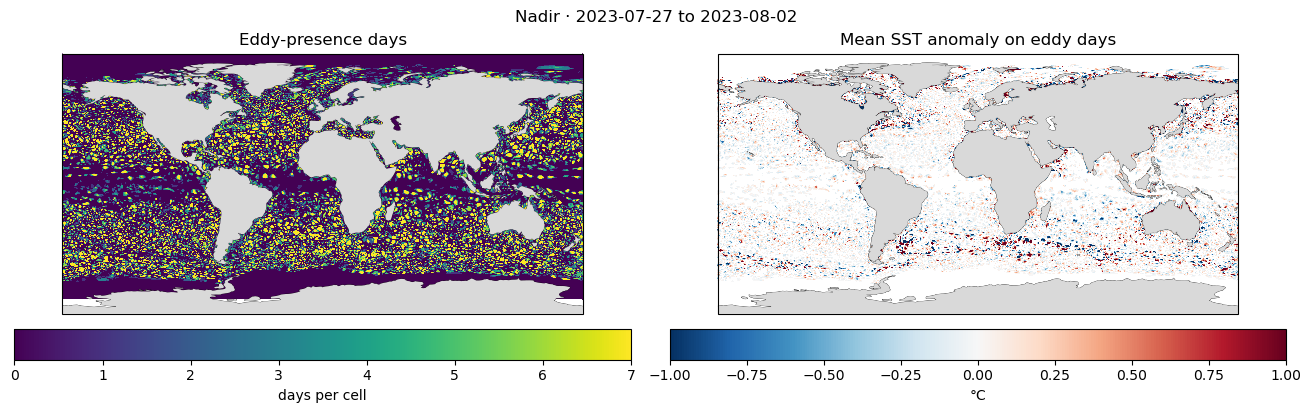

In [14]:
week = nadir_eddies.isel(time=slice(0, n_days))
mask = week["eddies"]
sst = week[sst_var]

# Select the two axes from the stored latitude/longitude grids.
lon = (week["lon"].isel(time=0, y=0).values + 180) % 360 - 180
lat = week["lat"].isel(time=0, x=0).values
x_order = np.argsort(lon)
y_order = np.argsort(lat)

valid = (mask == 0) | (mask == 1)
present = mask == 1
eddy_days = present.sum("time").where(valid.any("time"))
# Also exclude the large NetCDF fill value preserved in the metadata.
mean_sst = sst.where(present & (abs(sst) < 1e30)).mean("time")

fig, axes = plt.subplots(
    1, 2, figsize=(13, 4), layout="constrained",
    subplot_kw={"projection": crs},
)
panels = [
    (eddy_days, "Eddy-presence days", "days per cell", "viridis", 0, n_days),
    (mean_sst, "Mean SST anomaly on eddy days", "°C", "RdBu_r", -1, 1),
]

for ax, (field, title, units, cmap, low, high) in zip(axes, panels):
    plotted = field.transpose("y", "x").values[np.ix_(y_order, x_order)]
    image = ax.pcolormesh(
        lon[x_order], lat[y_order], plotted, transform=crs,
        shading="auto", cmap=cmap, vmin=low, vmax=high, rasterized=True,
    )
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="0.85", zorder=2)
    ax.coastlines(linewidth=0.4)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, orientation="horizontal", label=units)

start, end = week.time.values[[0, -1]].astype("datetime64[D]")
fig.suptitle(f"Nadir · {start} to {end}")

## Swot Eddies

In [7]:
swot_eddies = xr.open_zarr(swot_href)
swot_eddies

<xarray.Dataset> Size: 27GB
Dimensions:                          (time: 280, y: 1701, x: 3600)
Coordinates:
  * time                             (time) datetime64[ns] 2kB 2023-07-27 ......
Dimensions without coordinates: y, x
Data variables:
    eddies                           (time, y, x) float32 7GB dask.array<chunksize=(5, 1701, 3600), meta=np.ndarray>
    lat                              (time, y, x) float32 7GB dask.array<chunksize=(5, 1701, 3600), meta=np.ndarray>
    lon                              (time, y, x) float32 7GB dask.array<chunksize=(5, 1701, 3600), meta=np.ndarray>
    sea-surface-temperature-anomaly  (time, y, x) float32 7GB dask.array<chunksize=(5, 1701, 3600), meta=np.ndarray>
Attributes:
    history:  Wed Sep 23 14:47:08 2026: ncks -x -v SSH,temp,temp_noeddy Detec...
    NCO:      netCDF Operators version 5.0.6 (Homepage = http://nco.sf.net, C...

In [ ]:
week = swot_eddies.isel(time=slice(0, n_days))
mask = week["eddies"]
sst = week[sst_var]

# Select the two axes from the stored latitude/longitude grids.
lon = (week["lon"].isel(time=0, y=0).values + 180) % 360 - 180
lat = week["lat"].isel(time=0, x=0).values
x_order = np.argsort(lon)
y_order = np.argsort(lat)

valid = (mask == 0) | (mask == 1)
present = mask == 1
eddy_days = present.sum("time").where(valid.any("time"))
# Also exclude the large NetCDF fill value preserved in the metadata.
mean_sst = sst.where(present & (abs(sst) < 1e30)).mean("time")

fig, axes = plt.subplots(
    1, 2, figsize=(13, 4), layout="constrained",
    subplot_kw={"projection": crs},
)
panels = [
    (eddy_days, "Eddy-presence days", "days per cell", "viridis", 0, n_days),
    (mean_sst, "Mean SST anomaly on eddy days", "°C", "RdBu_r", -1, 1),
]

for ax, (field, title, units, cmap, low, high) in zip(axes, panels):
    plotted = field.transpose("y", "x").values[np.ix_(y_order, x_order)]
    image = ax.pcolormesh(
        lon[x_order], lat[y_order], plotted, transform=crs,
        shading="auto", cmap=cmap, vmin=low, vmax=high, rasterized=True,
    )
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="0.85", zorder=2)
    ax.coastlines(linewidth=0.4)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, orientation="horizontal", label=units)

start, end = week.time.values[[0, -1]].astype("datetime64[D]")
fig.suptitle(f"SWOT · {start} to {end}")